# DreamZero: a world action model that imagines video and acts

[DreamZero](https://arxiv.org/abs/2602.15922) (Ye et al., *World Action Models are Zero-shot Policies*, 2026) is a **world action model**: one autoregressive diffusion transformer denoises the next chunk of video *and* the actions that produce it, with a single flow-matching loss. The paper fine-tunes the 14B Wan2.1 image-to-video model on robot data; this notebook trains the same recipe from scratch, at small scale, in the latent space of the frozen Wan 2.1 video VAE:

1. play data from a **UR10e arm** simulated in [MuJoCo](https://mujoco.org) (`pip install torch-world[action,wam]`), encoded once into Wan VAE latents;
2. chunk-wise teacher-forced training of `DreamZero` on 4 chunks of 2 latent frames (8 video frames) and 8 actions;
3. what it imagines: decoded video rollouts against the real ones;
4. closed-loop goal reaching, where real observations replace the imagined video after every chunk, against [LeWAM](../../models/jepa/lewam.md) trained on the same data.

In [1]:
import torch
from torch.utils.data import DataLoader

from torch_world import evaluation, metrics, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import RobotCube
from torch_world.models import DreamZero, LeWAM
from torch_world.nn import CLSEncoder, VideoVAE
from torch_world.planning import DreamZeroPolicy, LeWAMPlanner, WAMPlanner

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

## Play data
A noisy scripted policy picks the cube up and puts it down at random spots, like OGBench's `play` datasets; actions move the gripper by up to 10 cm and open or close it, five times a second. Each 64-step episode is cut into clips of 33 frames and the 32 actions between them, starting every 8 steps.

512 episodes x 5 clips of 33 frames


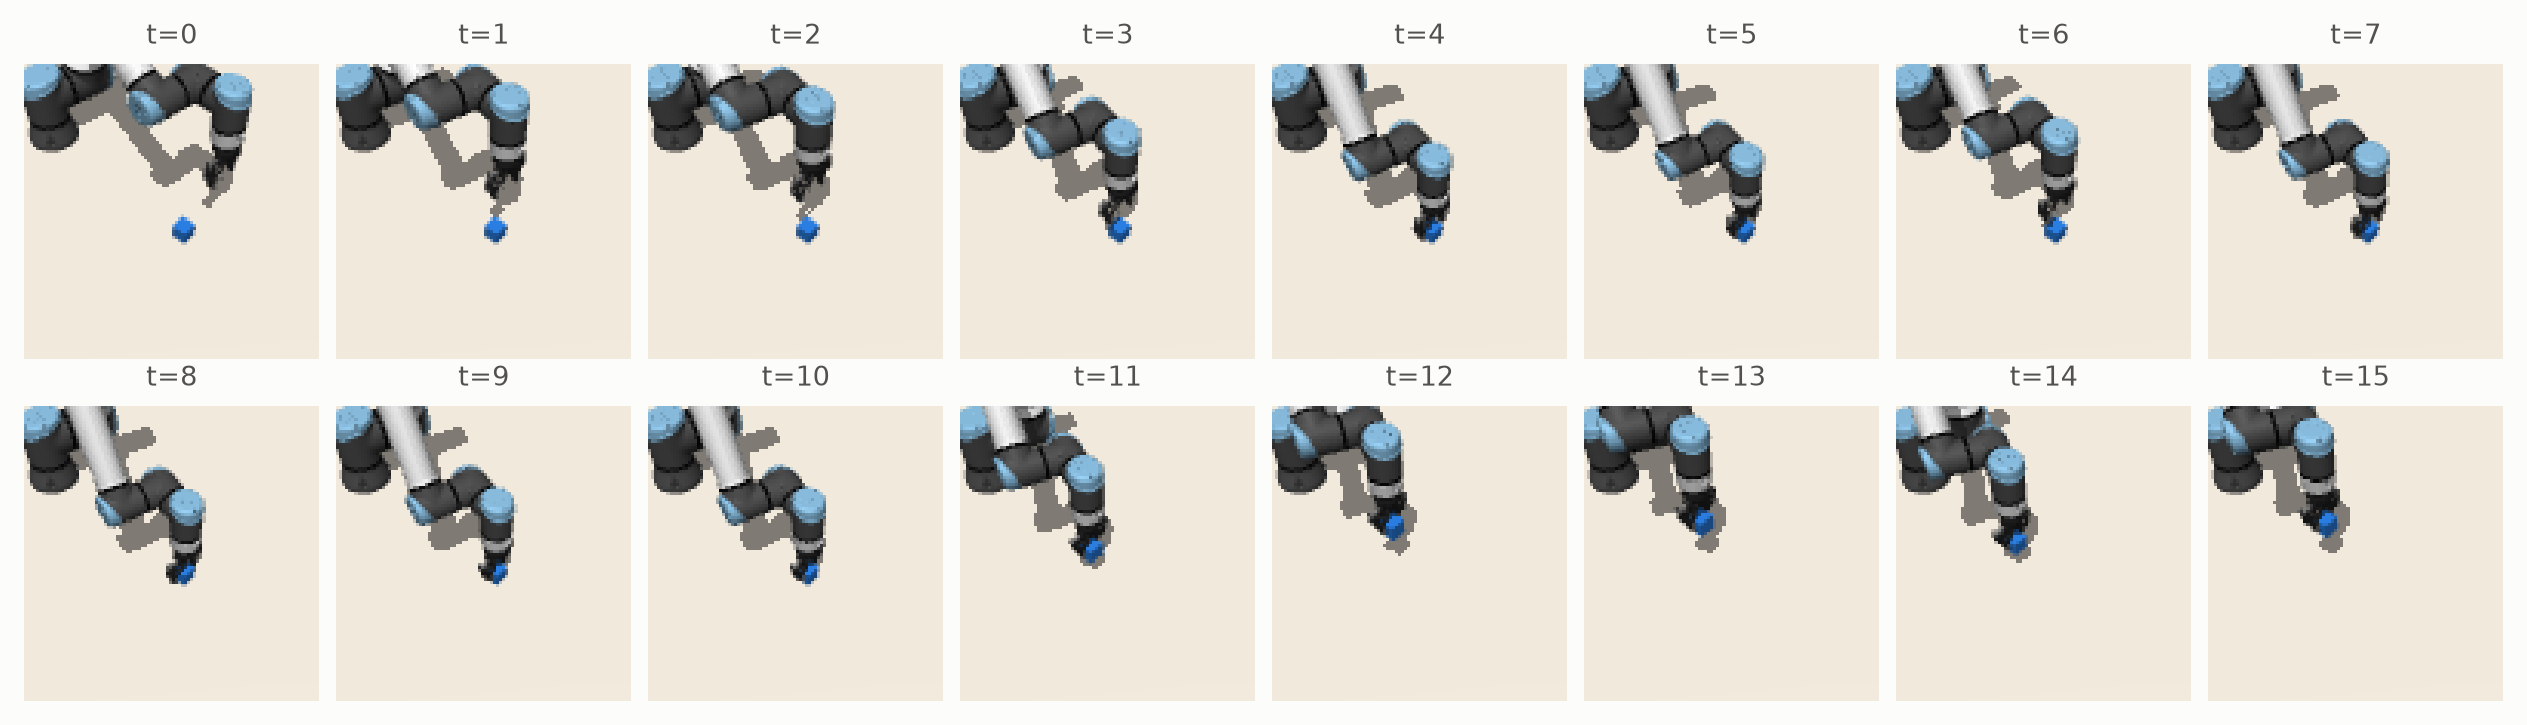

In [2]:
ROBOT = dict(robot="ur10e", size=96, control_dt=0.2, max_step=0.1)
FRAMES, ACTIONS, STRIDE = 33, 32, 8
data = RobotCube(batch_size=512, **ROBOT).collect(FRAMES + 32, generator=torch.Generator().manual_seed(0))
starts = range(0, data["actions"].size(1) - ACTIONS + 1, STRIDE)
print(f"{len(data['pixels'])} episodes x {len(starts)} clips of {FRAMES} frames")
plots.images(data["pixels"][2, :16], [f"t={t}" for t in range(16)], size=1.3)

## Wan 2.1 video VAE latents
The causal Wan VAE keeps the first frame alone and packs every following 4 frames into one latent frame, 8x smaller in each spatial direction with 16 channels: a 33-frame clip at 96 px becomes 9 latent frames of 16 x 12 x 12. Every clip is encoded once. The goal of a clip is its last frame, encoded on its own as hindsight relabeling.

/clusterhome/kleyton/pytorch-world-dreamzero-20261020/pydeps/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Cannot initialize model with low cpu memory usage because `accelerate` was not found in the environment. Defaulting to `low_cpu_mem_usage=False`. It is strongly recommended to install `accelerate` for faster and less memory-intense model loading. You can do so with: 
```
pip install accelerate
```
.


/clusterhome/kleyton/pytorch-world-dreamzero-20261020/pydeps/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


latents (2560, 9, 16, 12, 12) goals (2560, 16, 12, 12) actions (2560, 32, 4)


VAE reconstruction PSNR 26.1 dB


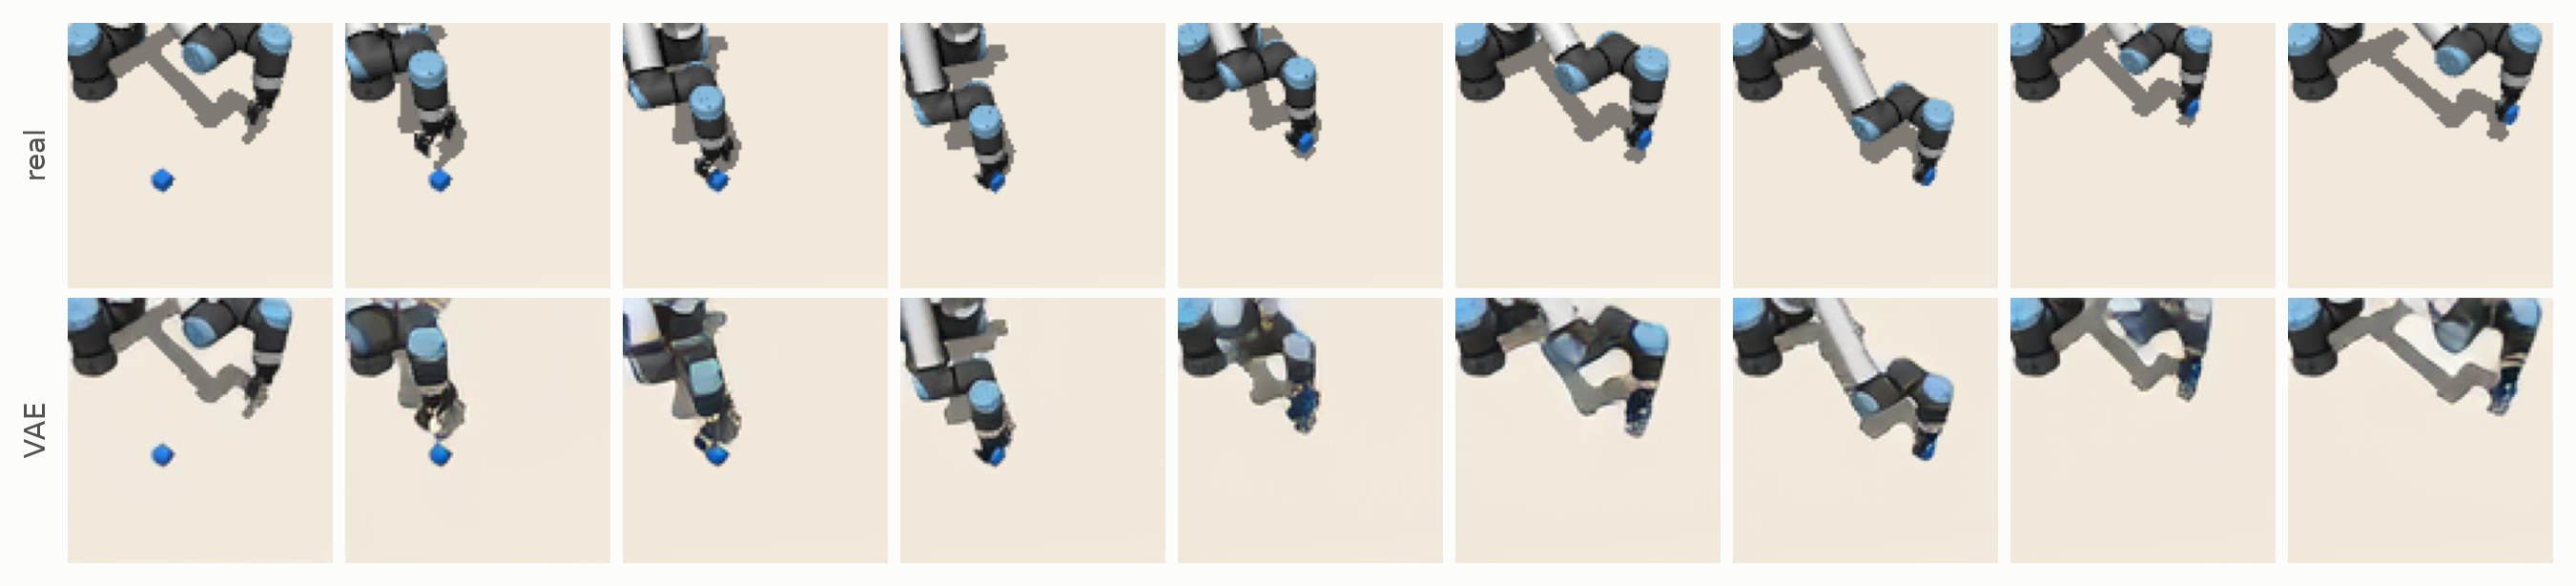

In [3]:
vae = VideoVAE.from_pretrained().to(device)


@torch.no_grad()
def encode(clips, batch=32):
    return torch.cat([vae.encode(c.to(device)) for c in clips.split(batch)])


latents, goals, actions = [], [], []
for s in starts:
    clip = data["pixels"][:, s : s + FRAMES]
    latents.append(encode(clip))
    goals.append(encode(clip[:, -1:])[:, 0])
    actions.append(data["actions"][:, s : s + ACTIONS].to(device))
latents, goals, actions = torch.cat(latents), torch.cat(goals), torch.cat(actions)
print("latents", tuple(latents.shape), "goals", tuple(goals.shape), "actions", tuple(actions.shape))

with torch.no_grad():
    clip = data["pixels"][:4, :FRAMES].to(device)
    recon = vae.decode(vae.encode(clip))
print(f"VAE reconstruction PSNR {metrics.psnr(recon, clip).mean():.1f} dB")
plots.images(torch.cat([clip[0, ::4], recon[0, ::4]]).cpu(), ncols=9, size=1.2, rows=["real", "VAE"])

## Model and training
Each chunk is 2 latent frames (36 tokens each with 2 x 2 patches) and 8 action tokens. Every chunk of a clip gets its own flow time; video and actions within a chunk share it. A noisy chunk attends to the anchor frame, the goal frame, the *clean* earlier chunks and itself, so one forward pass trains all four autoregressive steps (teacher forcing). The state encoder of the paper is left out: the arm's state is visible in the images.

22.2M trainable parameters


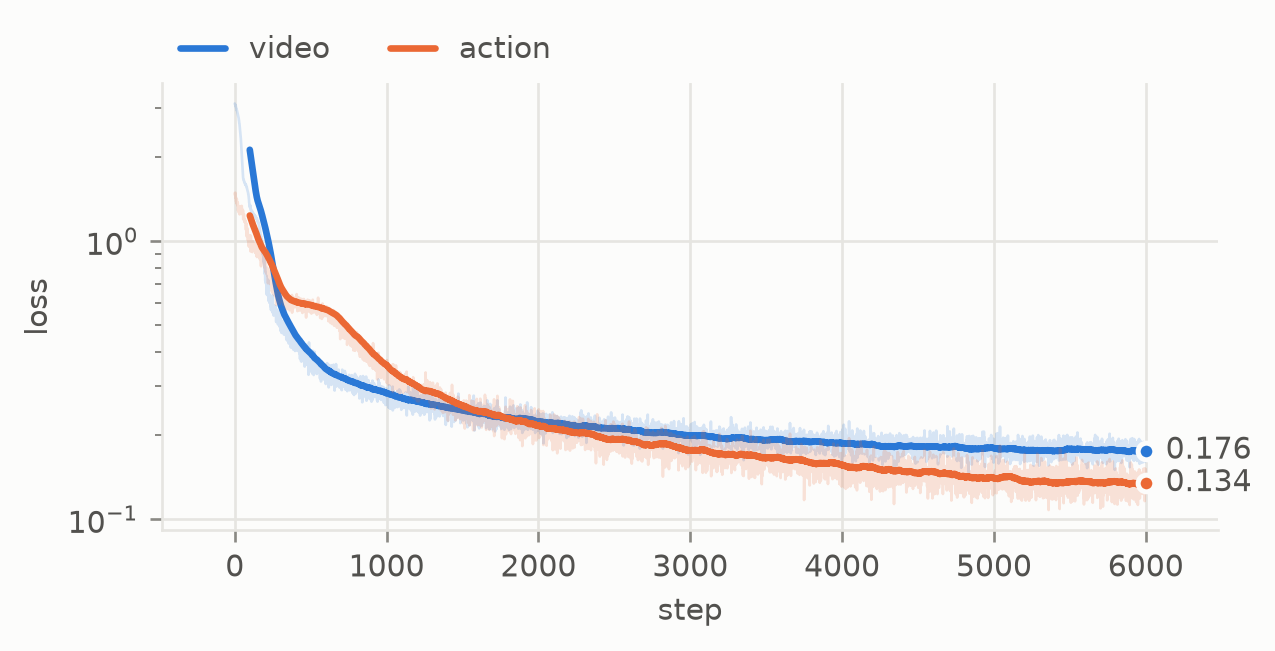

In [4]:
model = DreamZero(
    16, (12, 12), action_dim=4, patch_size=2, chunk_frames=2, chunk_actions=8, num_chunks=4,
    dim=384, depth=8, num_heads=6, flow_steps=16, goal_conditioned=True, autoencoder=vae,
).to(device)
params = [p for p in model.parameters() if p.requires_grad]
print(f"{sum(p.numel() for p in params) / 1e6:.1f}M trainable parameters")

EPOCHS, BATCH = 150, 64
steps = EPOCHS * (len(latents) // BATCH)
opt = torch.optim.AdamW(params, lr=3e-4, weight_decay=1e-3)
schedule = torch.optim.lr_scheduler.OneCycleLR(opt, 3e-4, total_steps=steps, pct_start=0.05)
log = {"video": [], "action": []}
for epoch in range(EPOCHS):
    for idx in torch.randperm(len(latents), device=device)[: steps // EPOCHS * BATCH].view(-1, BATCH):
        with torch.autocast(device, torch.bfloat16, enabled=device == "cuda"):
            out = model(latents[idx], actions[idx], goal=goals[idx])
        opt.zero_grad()
        out["loss"].backward()
        torch.nn.utils.clip_grad_norm_(params, 1.0)
        opt.step()
        schedule.step()
        log["video"].append(out["video_loss"].item())
        log["action"].append(out["action_loss"].item())
model.eval()
plots.curves(log, smooth=100)

## What it imagines
On held-out play data, the model sees the anchor frame and the first real chunk (9 video frames), then rolls out the next three chunks from the recorded actions, chunk by chunk, feeding back its own predicted latents. The VAE decodes the imagined latents. "Nothing changes" repeats the last real frame.

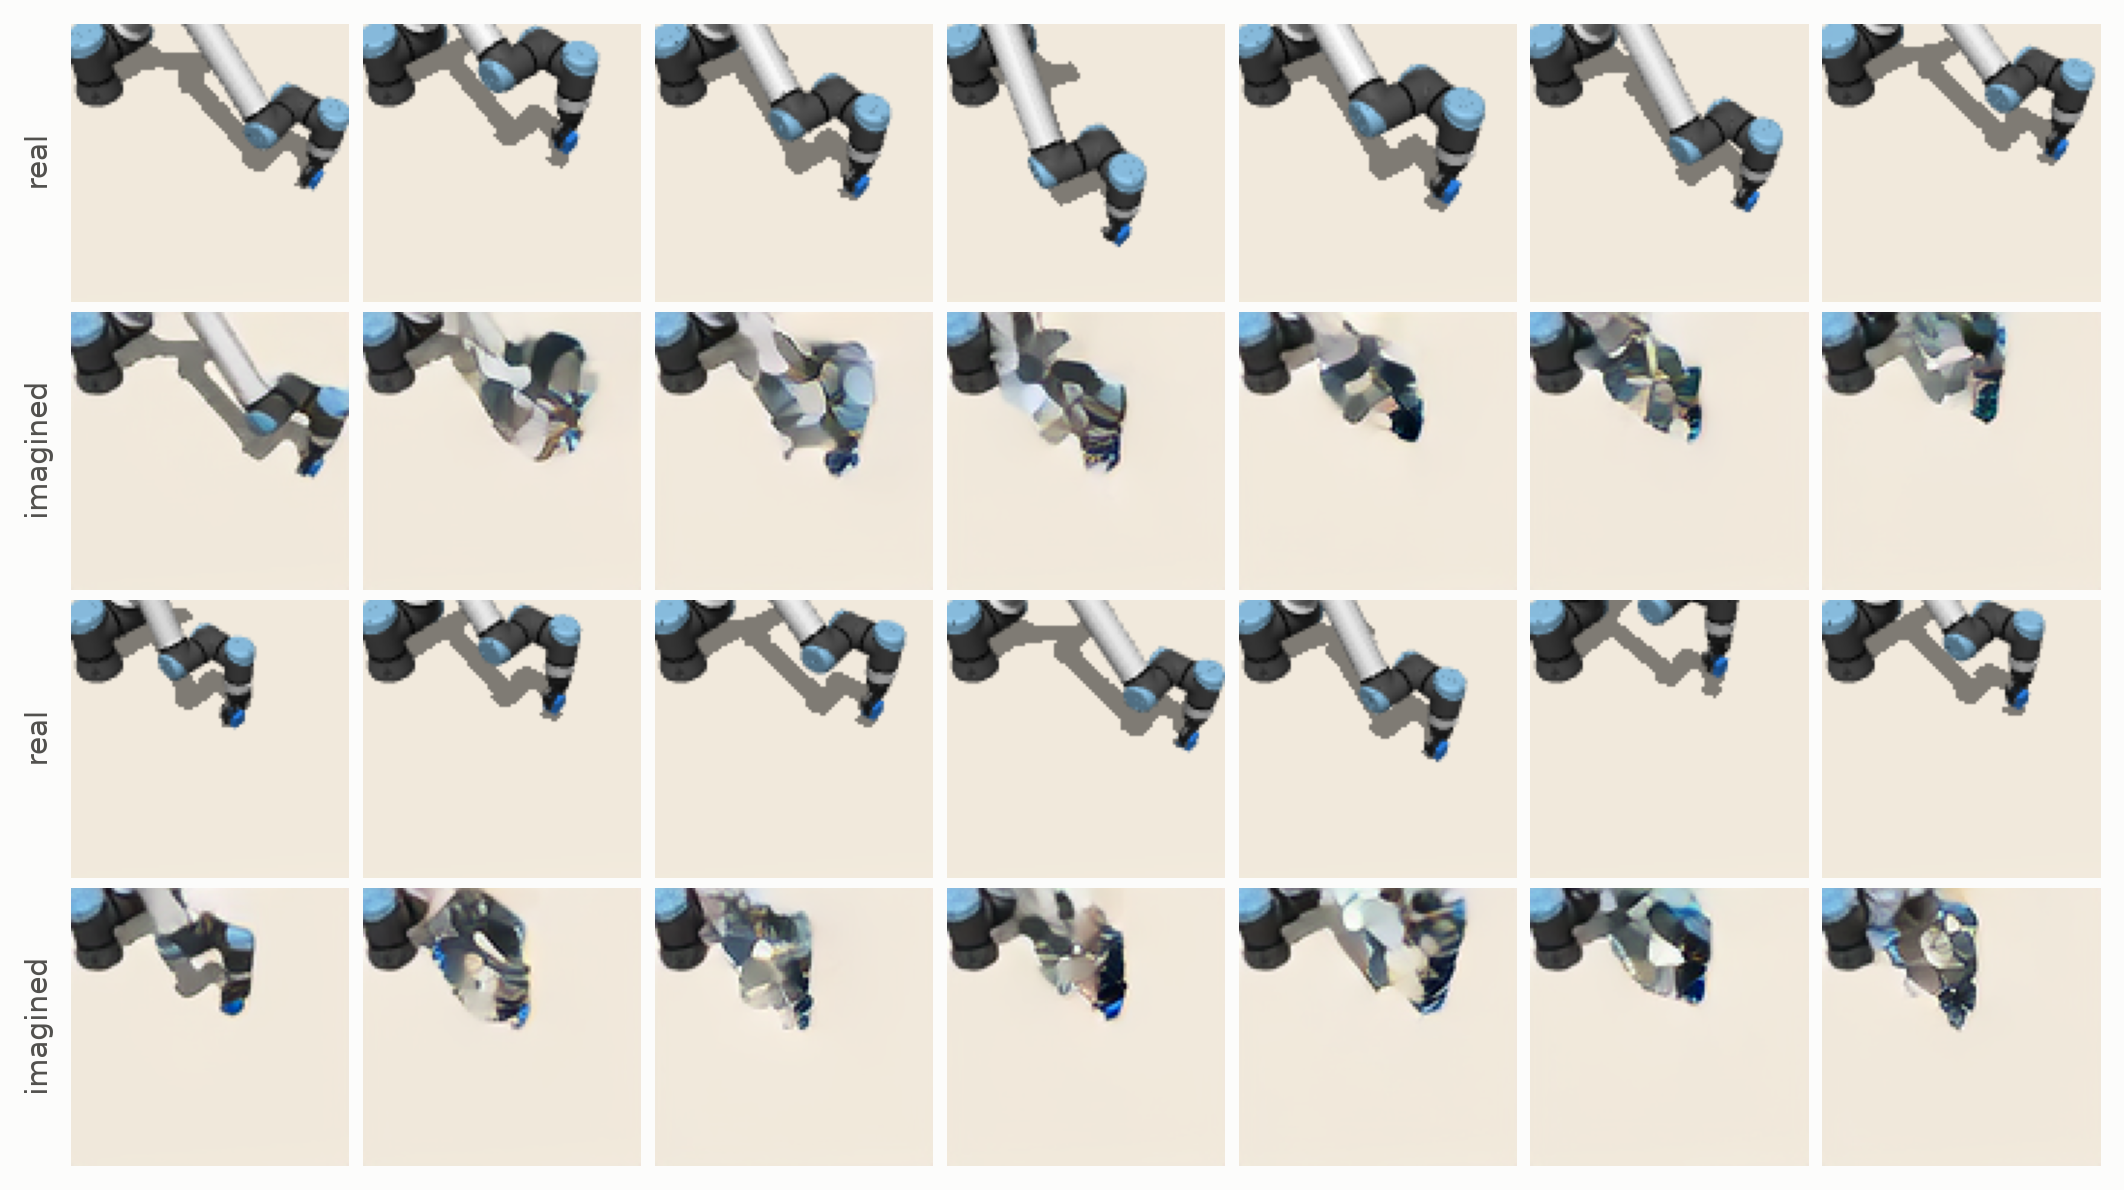

In [5]:
held_out = RobotCube(batch_size=32, **ROBOT).collect(FRAMES, generator=torch.Generator().manual_seed(5))
real_pixels, real_actions = held_out["pixels"].to(device), held_out["actions"].to(device)
with torch.no_grad():
    real = vae.encode(real_pixels)
    goal = vae.encode(real_pixels[:, -1:])[:, 0]
    imagined = model.rollout(real[:, :3], real_actions[:, 8:32], goal=goal, past_actions=real_actions[:, :8], generator=torch.Generator(device).manual_seed(0))
    video = vae.decode(imagined)
frames = range(9, FRAMES)
still = real_pixels[:, 8:9].expand(-1, FRAMES - 9, -1, -1, -1)
plots.curves(
    {
        "DreamZero": (frames, metrics.psnr(video[:, 9:], real_pixels[:, 9:]).mean(0).tolist()),
        "nothing changes": (frames, metrics.psnr(still, real_pixels[:, 9:]).mean(0).tolist()),
    },
    smooth=1, logy=False, ylabel="PSNR (dB)",
)
show = list(range(8, FRAMES, 4))
plots.images(torch.cat([real_pixels[0, show], video[0, show], real_pixels[1, show], video[1, show]]).cpu(), ncols=len(show), size=1.2, rows=["real", "imagined", "real", "imagined"])

## LeWAM on the same data
[LeWAM](../../models/jepa/lewam.md) also predicts the future and its actions jointly, but in a learned JEPA latent space instead of video: regression dynamics on embeddings, a flow-matching action head and SIGReg. It is trained on 11-frame windows of the same episodes (3 history frames, an 8-action chunk), with the window's last frame as its goal.

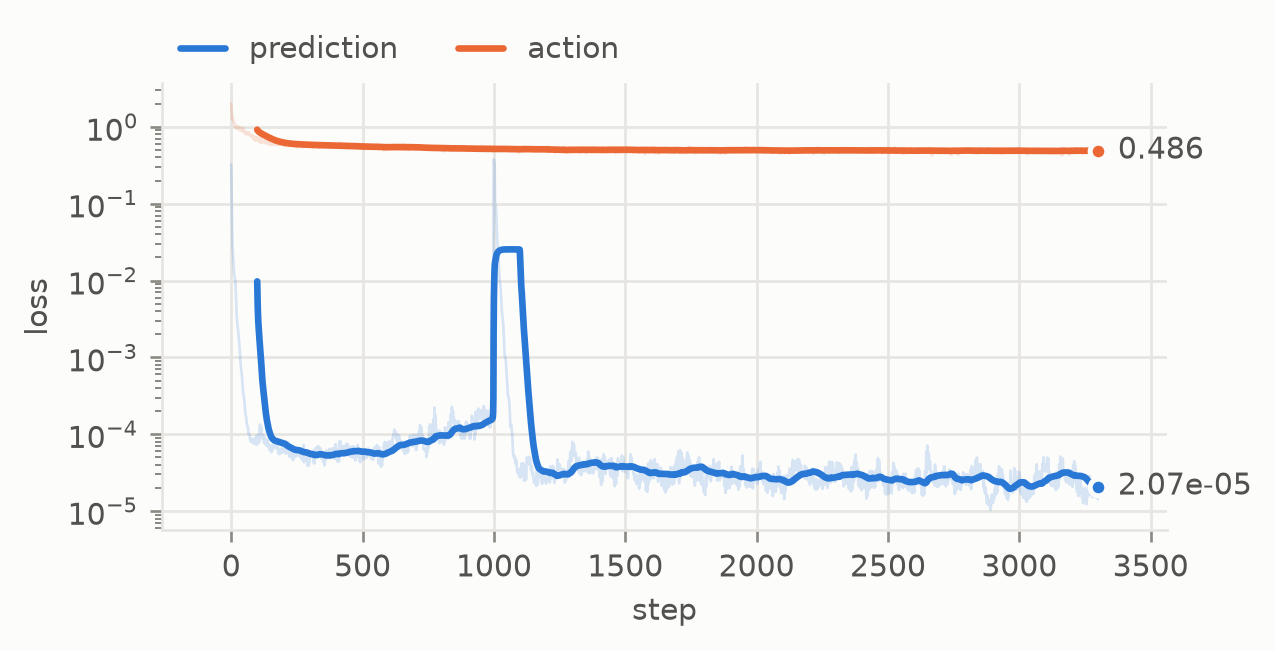

In [6]:
HISTORY, CHUNK = 3, 8
loader = DataLoader(TrajectoryDataset({k: v for k, v in data.items()}, HISTORY + CHUNK), batch_size=256, shuffle=True, drop_last=True)
lewam = LeWAM(
    CLSEncoder(img_size=96, patch_size=12, embed_dim=192, depth=6, num_heads=6), action_dim=4, embed_dim=192,
    history=HISTORY, chunk_size=CHUNK, dim=192, depth=4, num_heads=4, mlp_dim=768,
).to(device)
opt = torch.optim.AdamW(lewam.parameters(), lr=5e-4, weight_decay=1e-3)
lewam_log = {"prediction": [], "action": []}
for epoch in range(30):
    for batch in loader:
        pixels = batch["pixels"].to(device)
        out = lewam(pixels, batch["actions"].to(device), goal_pixels=pixels[:, -1])
        opt.zero_grad()
        out["loss"].backward()
        opt.step()
        lewam_log["prediction"].append(out["pred_loss"].item())
        lewam_log["action"].append(out["action_loss"].item())
lewam.eval()
plots.curves(lewam_log, smooth=100)

## Reach goal images in closed loop
Each task gives a start and the image of a goal pose for the open gripper; success is within 5 cm after 16 steps.

- **DreamZero policy**: sample a chunk of 8 actions with the joint flow (16 Euler steps), execute it, then encode the *real* frames of that chunk into the context in place of the imagined ones, as DreamZero does with its KV cache.
- **DreamZero + ranking**: 8 sampled chunks, ranked by how close the model's predicted video ends to the goal (`WAMPlanner`).
- **LeWAM policy**: LeWAM's learned policy, replanned after every action.

                               success  reached   steps  final distance  progress     SPL  smoothness  ms / step
DreamZero policy          3% [1%, 16%]       9%    8.67           0.235   -0.0542 0.00624        1.05        183
DreamZero + ranking       0% [0%, 11%]       9%    8.33           0.219     0.119       0       0.978   1.36e+03
LeWAM policy              3% [1%, 16%]       6%      15           0.288   -0.0868 0.00327        1.29       26.3
scripted expert       100% [89%, 100%]     100%    2.34        4.71e-08         1   0.963       0.113      0.119
random actions            0% [0%, 11%]       0%     nan           0.321    -0.394       0        1.57     0.0833


/clusterhome/kleyton/pytorch-world/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


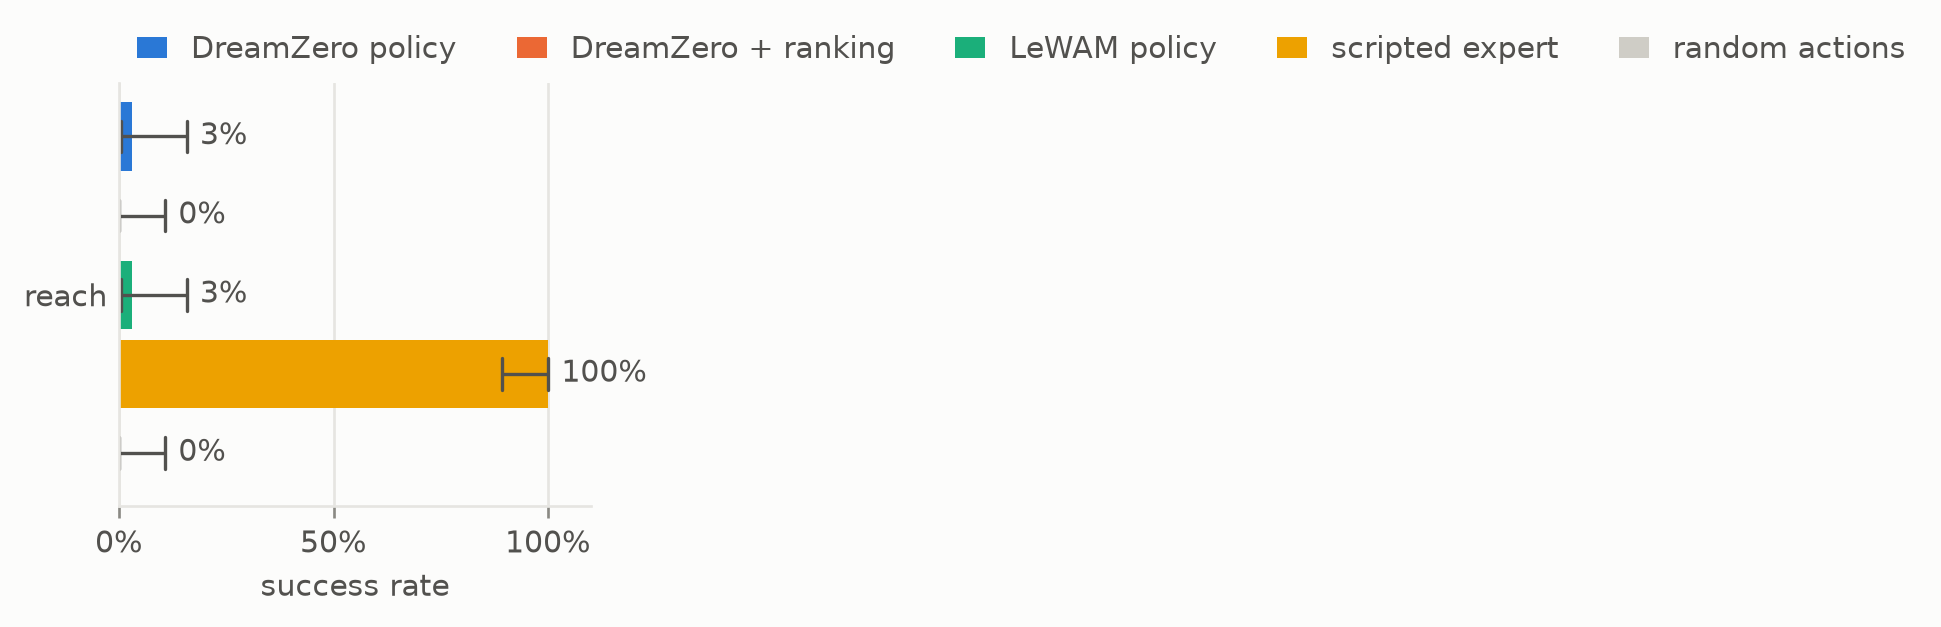

In [7]:
class LeWAMControl:
    def __init__(self, goal_images):
        with torch.no_grad():
            self.goal = lewam.encode(goal_images[:, None].to(device))[:, 0]
        self.frames = []

    @torch.no_grad()
    def __call__(self, obs):
        self.frames = (self.frames + [obs.to(device)])[-HISTORY:]
        missing = HISTORY - len(self.frames)
        pad = torch.tensor([True] * missing + [False] * len(self.frames), device=device).expand(len(obs), -1)
        z = lewam.encode(torch.stack([self.frames[0]] * missing + self.frames, 1))
        return LeWAMPlanner()(lewam, z, self.goal, history_pad=pad)[:, 0].cpu()


def dreamzero(goal_images, plan=None):
    with torch.no_grad():
        goal = vae.encode(goal_images[:, None].to(device))[:, 0]
    policy = DreamZeroPolicy(model, goal, plan=plan, generator=torch.Generator(device).manual_seed(0))
    return lambda obs: policy(obs.to(device)).cpu()


env = RobotCube(batch_size=32, task="reach", **ROBOT)
start, goal_state = env.tasks(generator=torch.Generator().manual_seed(1))
goal_images = env.render(goal_state)
policies = {
    "DreamZero policy": dreamzero(goal_images),
    "DreamZero + ranking": dreamzero(goal_images, WAMPlanner(num_samples=8)),
    "LeWAM policy": LeWAMControl(goal_images),
    "scripted expert": lambda obs: env.scripted(goal_state),
    "random actions": evaluation.random_policy(env),
}
run = evaluation.goal_reaching(env, policies, start, goal_state, 16, record=lambda e: e.render(size=160, goal=goal_state))
print(run)
plots.bars({"reach": run.intervals()}, xlabel="success rate", baseline="random actions")

Episodes of the DreamZero policy. The translucent orange gripper marks the goal (videos only; the model sees the plain scene):


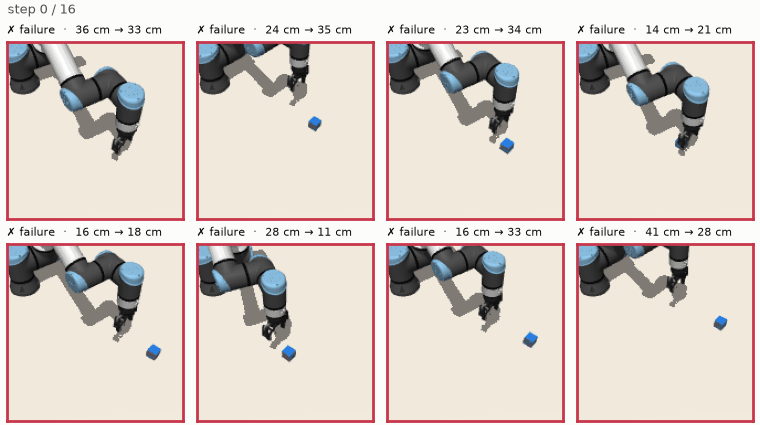

In [8]:
plots.episodes(run.frames["DreamZero policy"][:8], run.success["DreamZero policy"][:8], [f"{100 * d:.0f} cm → {100 * e:.0f} cm" for d, e in run.distances["DreamZero policy"][:8, [0, -1]].tolist()])

## What is and is not reproduced
This is the DreamZero *recipe* at toy scale: joint video-action flow matching on Wan VAE latents, chunk-wise teacher forcing, autoregressive chunks and real-observation replacement in the context. It is not the paper's model: no 14B pre-trained video backbone, no language conditioning, no multi-view inputs, Euler integration instead of Flow UniPC, and no action smoothing or DiT caching. See the [model card](../../models/wam/dreamzero.md) for the full list.